<a href="https://colab.research.google.com/github/vishwa24816/Kelly-Criterion/blob/main/Kelly_Criterion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Kelly-Style Position Sizing on AAPL Daily Returns

# Goal: Extend the coin-flip betting experiment to real market data. The main question is whether bet size matters more than whether an edge exists, and how much estimation error in the edge threatens a Kelly-sized strategy.

# Disclaimer: This notebook is educational. It is not investment advice, and it does not recommend trading AAPL or any other security.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import yfinance as yf

SEED = 42
rng = np.random.default_rng(SEED)

TICKER = "AAPL"
YEARS = 10
RISK_FREE_RATE = 0.0  # stated explicitly: Sharpe uses rf = 0 for simplicity

print(f"numpy {np.__version__} | pandas {pd.__version__} | yfinance {yf.__version__}")

numpy 2.1.3 | pandas 2.2.3 | yfinance 0.2.66


In [2]:
## 2. Download AAPL Data

# We pull daily adjusted close prices over a configurable window ending at the most recent trading day. Recent yfinance versions return MultiIndex columns, so we flatten them. If the download fails, we raise a clear error instead of continuing with empty data.

def download_prices(ticker, years):
    end = pd.Timestamp.today().normalize()
    start = end - pd.DateOffset(years=years)
    try:
        raw = yf.download(ticker, start=start, end=end, auto_adjust=True,
                          progress=False)
    except Exception as exc:
        raise RuntimeError(f"yfinance download failed for {ticker}: {exc}") from exc

    if raw is None or raw.empty:
        raise RuntimeError(
            f"No data returned for {ticker}. Check your internet connection "
            "or the ticker symbol, then rerun."
        )

    # Handle MultiIndex columns from recent yfinance versions
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)

    prices = raw[["Close"]].rename(columns={"Close": ticker})
    prices.index = pd.to_datetime(prices.index)
    return prices

prices_raw = download_prices(TICKER, YEARS)

print("First rows:")
print(prices_raw.head())
print("\nLast rows:")
print(prices_raw.tail())
print(f"\nNumber of observations: {len(prices_raw)}")

First rows:
Price            AAPL
Date                 
2016-10-31  25.964968
2016-11-01  25.496157
2016-11-02  25.519026
2016-11-03  25.245501
2016-11-04  25.017939

Last rows:
Price             AAPL
Date                  
2026-10-22  348.220001
2026-10-23  347.730011
2026-10-26  343.910004
2026-10-27  347.100006
2026-10-28  343.829987

Number of observations: 2512


      missing_before: 0
 missing_after_ffill: 0
     duplicate_dates: 0
        non_positive: 0

Clean observations: 2512


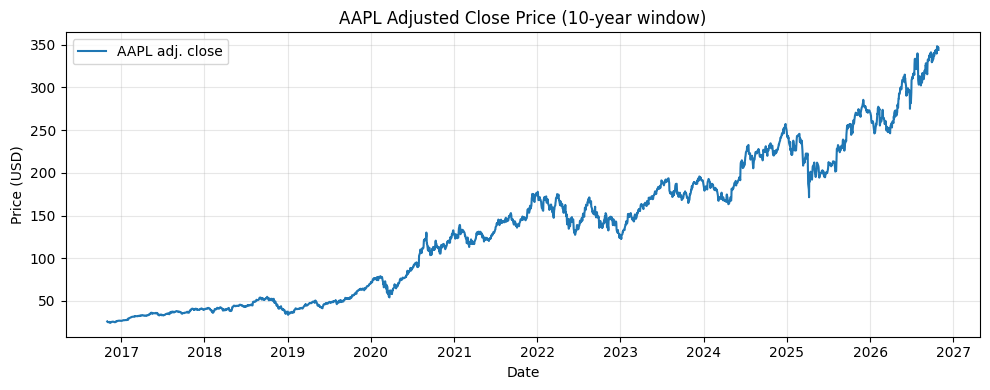

In [3]:
## 3. Data Quality Checks

# Before computing returns we check for three problems: missing values, duplicate dates, and non-positive prices. Missing prices are forward-filled because a gap usually means no trade occurred, and the last known price is the best available estimate. Duplicate dates are dropped, keeping the first occurrence. Non-positive prices are invalid for returns, so they are dropped. Every action is printed so the choice is visible.

prices = prices_raw.copy()
report = {}

report["missing_before"] = int(prices[TICKER].isna().sum())
prices[TICKER] = prices[TICKER].ffill()
report["missing_after_ffill"] = int(prices[TICKER].isna().sum())
prices = prices.dropna()

report["duplicate_dates"] = int(prices.index.duplicated().sum())
prices = prices[~prices.index.duplicated(keep="first")]

report["non_positive"] = int((prices[TICKER] <= 0).sum())
prices = prices[prices[TICKER] > 0]

prices = prices.sort_index()

for k, v in report.items():
    print(f"{k:>20}: {v}")
print(f"\nClean observations: {len(prices)}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(prices.index, prices[TICKER], color="tab:blue", label=f"{TICKER} adj. close")
ax.set_title(f"{TICKER} Adjusted Close Price ({YEARS}-year window)")
ax.set_xlabel("Date")
ax.set_ylabel("Price (USD)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Risk-free rate used in Sharpe: 0 (stated explicitly)
                    simple      log
mean               0.00120  0.00103
std                0.01836  0.01834
skewness           0.12061 -0.11742
excess_kurtosis    6.81601  6.60126
annualized_sharpe  1.03565  0.89048


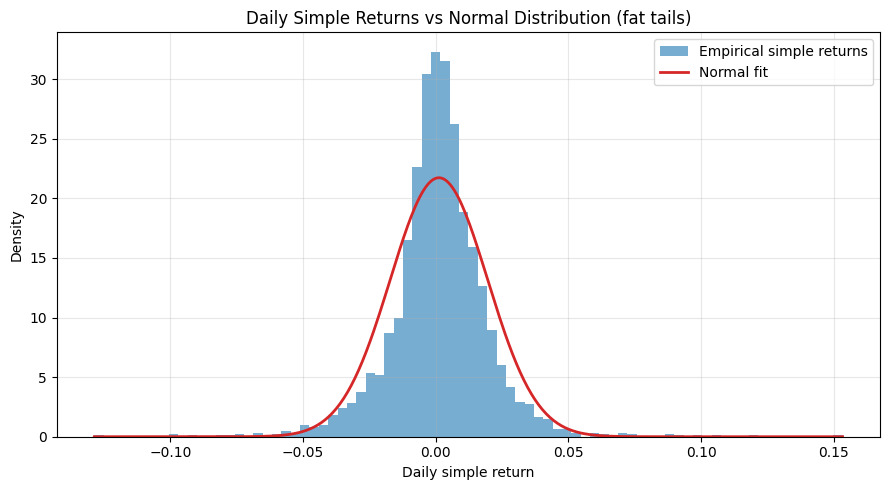

In [4]:
## 4. Returns and Basic Statistics

# Log returns are additive over time and are the usual choice for modeling. Simple returns are what a bettor actually wins or loses on each day, so we need both. Fat tails matter here because a normal distribution understates the chance of extreme days, and that changes how much risk a Kelly bet carries. The Sharpe ratio is annualized with 252 trading days and a risk-free rate of 0.

simple_ret = prices[TICKER].pct_change().dropna()
log_ret = np.log(prices[TICKER]).diff().dropna()

def summary_stats(r):
    ann_mean = r.mean() * 252
    ann_std = r.std(ddof=1) * np.sqrt(252)
    sharpe = (ann_mean - RISK_FREE_RATE) / ann_std
    return {
        "mean": r.mean(),
        "std": r.std(ddof=1),
        "skewness": stats.skew(r),
        "excess_kurtosis": stats.kurtosis(r),
        "annualized_sharpe": sharpe,
    }

stats_table = pd.DataFrame({
    "simple": summary_stats(simple_ret),
    "log": summary_stats(log_ret),
})
print("Risk-free rate used in Sharpe: 0 (stated explicitly)")
print(stats_table.round(5))

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(simple_ret, bins=80, density=True, alpha=0.6, color="tab:blue",
        label="Empirical simple returns")
x = np.linspace(simple_ret.min(), simple_ret.max(), 400)
ax.plot(x, stats.norm.pdf(x, simple_ret.mean(), simple_ret.std(ddof=1)),
        color="tab:red", lw=2, label="Normal fit")
ax.set_title("Daily Simple Returns vs Normal Distribution (fat tails)")
ax.set_xlabel("Daily simple return")
ax.set_ylabel("Density")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
## 5. Estimate the Edge

# We define a "win" as a day with a positive simple return. Payoff ratio b is the average win divided by the average loss in magnitude. For the coin flip, b = 1, so the Kelly fraction reduces to f* = p − q. With real returns b can differ from 1, so the general formula is

# f* = (bp − q) / b,  where q = 1 − p.

# AAPL daily returns are not independent coin flips. They show volatility clustering, autocorrelation in magnitude, and regime shifts. The Kelly fraction below is therefore a plug-in estimate that assumes the edge is stable, which the later sections test.

wins = simple_ret[simple_ret > 0]
losses = simple_ret[simple_ret < 0]

p = len(wins) / len(simple_ret)
q = 1 - p
avg_win = wins.mean()
avg_loss = -losses.mean()   # magnitude
b = avg_win / avg_loss
kelly_f = (b * p - q) / b

print(f"Win rate p:           {p:.4f}")
print(f"Loss rate q:          {q:.4f}")
print(f"Average win:          {avg_win:.5f}")
print(f"Average loss (mag.):  {avg_loss:.5f}")
print(f"Payoff ratio b:       {b:.4f}")
print(f"Kelly fraction f*:    {kelly_f:.4f}")
print(f"Coin-flip f* (b=1):   {p - q:.4f}  (for comparison)")

Win rate p:           0.5372
Loss rate q:          0.4628
Average win:          0.01291
Average loss (mag.):  0.01246
Payoff ratio b:       1.0358
Kelly fraction f*:    0.0905
Coin-flip f* (b=1):   0.0745  (for comparison)


Win rate p:      point 0.5372 | 90% CI [0.5205, 0.5536]
Kelly fraction:  point 0.0905 | 90% CI [0.0450, 0.1338]
Kelly CI width / point estimate: 0.98x


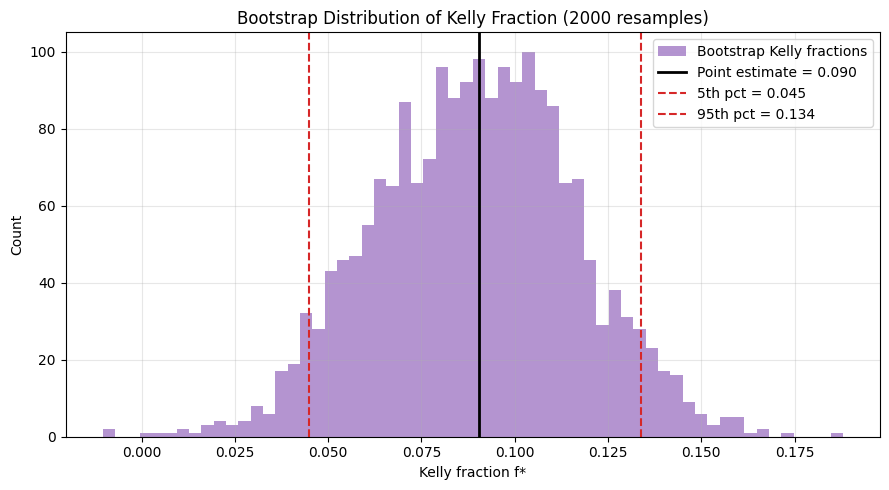

In [6]:
## 6. Estimation Uncertainty

# The point estimate of the Kelly fraction is only as good as the sample behind it. We bootstrap the daily returns (2,000 resamples with replacement) to get a sampling distribution for the win rate and the Kelly fraction. Wide intervals relative to the point estimate mean the edge is poorly identified, and sizing on it is risky.

N_BOOT = 2000
ret_arr = simple_ret.to_numpy()
n = len(ret_arr)

idx = rng.integers(0, n, size=(N_BOOT, n))
samples = ret_arr[idx]                       # shape (N_BOOT, n)

boot_win = (samples > 0).mean(axis=1)
pos = np.where(samples > 0, samples, np.nan)
neg = np.where(samples < 0, -samples, np.nan)
boot_b = np.nanmean(pos, axis=1) / np.nanmean(neg, axis=1)
boot_kelly = (boot_b * boot_win - (1 - boot_win)) / boot_b

p_lo, p_hi = np.percentile(boot_win, [5, 95])
k_lo, k_hi = np.percentile(boot_kelly, [5, 95])

print(f"Win rate p:      point {p:.4f} | 90% CI [{p_lo:.4f}, {p_hi:.4f}]")
print(f"Kelly fraction:  point {kelly_f:.4f} | 90% CI [{k_lo:.4f}, {k_hi:.4f}]")
print(f"Kelly CI width / point estimate: {(k_hi - k_lo) / abs(kelly_f):.2f}x")

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(boot_kelly, bins=60, color="tab:purple", alpha=0.7,
        label="Bootstrap Kelly fractions")
ax.axvline(kelly_f, color="black", lw=2, label=f"Point estimate = {kelly_f:.3f}")
ax.axvline(k_lo, color="tab:red", ls="--", label=f"5th pct = {k_lo:.3f}")
ax.axvline(k_hi, color="tab:red", ls="--", label=f"95th pct = {k_hi:.3f}")
ax.set_title(f"Bootstrap Distribution of Kelly Fraction ({N_BOOT} resamples)")
ax.set_xlabel("Kelly fraction f*")
ax.set_ylabel("Count")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
## 7. Coin-Flip Baseline

# We reproduce the original experiment: 1,000 players start with $100 and make 1,000 even-money bets with a 55% win rate. Each player uses a fixed fraction of current wealth. All bet sizes see the same flip sequences, so differences come from sizing alone, not luck of the draw.

N_PLAYERS = 1000
N_FLIPS = 1000
START = 100.0
WIN_P = 0.55
FRACTIONS = [0.02, 0.05, 0.10, 0.20, 0.40]

flips = rng.random((N_PLAYERS, N_FLIPS)) < WIN_P   # same flips for all sizes
outcomes = np.where(flips, 1.0, -1.0)              # even-money payoff

def run_fixed_fraction(step_returns, f, start=START):
    """Wealth path for a fixed fraction f applied to each step's return."""
    # Clip so wealth cannot go negative: a single bet loses at most all wealth
    growth = np.clip(1 + f * step_returns, 0.0, None)
    wealth = start * np.cumprod(growth, axis=1)
    return wealth

rows = []
for f in FRACTIONS:
    final = run_fixed_fraction(outcomes, f)[:, -1]
    rows.append({
        "bet_fraction": f,
        "median_final_wealth": np.median(final),
        "frac_below_start": np.mean(final < START),
        "frac_lost_over_99pct": np.mean(final < 0.01 * START),
    })

coin_table = pd.DataFrame(rows).set_index("bet_fraction")
print("Coin-flip baseline (55% win, even money, 1,000 players, 1,000 flips)")
print(coin_table.round(4))

Coin-flip baseline (55% win, even money, 1,000 players, 1,000 flips)
              median_final_wealth  frac_below_start  frac_lost_over_99pct
bet_fraction                                                             
0.02                     629.8000             0.002                 0.000
0.05                    4711.9705             0.007                 0.000
0.10                   18291.7923             0.052                 0.001
0.20                     130.6985             0.493                 0.220
0.40                       0.0000             1.000                 0.999


In [8]:
## 8. Fractional Betting on AAPL Returns

# Daily returns are resampled in blocks of 10 days. Block resampling keeps some of the autocorrelation and volatility clustering that single-day resampling destroys. Each player bets a fraction of wealth on each day's return, and wealth is clipped at zero so a player cannot go negative. We run the fixed fractions from the coin-flip case, then size at the in-sample Kelly fraction, and at 2x Kelly to show the cost of overbetting.

BLOCK = 10
N_DAYS = 1000

def block_bootstrap_paths(r, n_players, n_days, block, rng):
    """Resample contiguous blocks of returns for each player."""
    n_blocks = int(np.ceil(n_days / block))
    max_start = len(r) - block
    starts = rng.integers(0, max_start + 1, size=(n_players, n_blocks))
    offsets = np.arange(block)
    idx = (starts[:, :, None] + offsets).reshape(n_players, -1)[:, :n_days]
    return r[idx]

aapl_paths = block_bootstrap_paths(simple_ret.to_numpy(), N_PLAYERS, N_DAYS, BLOCK, rng)

def summarize_strategy(paths, f_label, f):
    wealth = run_fixed_fraction(paths, f)
    final = wealth[:, -1]
    return {
        "sizing": f_label,
        "bet_fraction": f,
        "median_final_wealth": np.median(final),
        "frac_below_start": np.mean(final < START),
        "frac_lost_over_99pct": np.mean(final < 0.01 * START),
    }

rows = [summarize_strategy(aapl_paths, f"fixed {f:.0%}", f) for f in FRACTIONS]
rows.append(summarize_strategy(aapl_paths, "in-sample Kelly", kelly_f))
rows.append(summarize_strategy(aapl_paths, "2x in-sample Kelly", 2 * kelly_f))

aapl_table = pd.DataFrame(rows).set_index("sizing")
print("AAPL block-bootstrap results (1,000 players, 1,000 days, block = 10)")
print(aapl_table.round(4))

AAPL block-bootstrap results (1,000 players, 1,000 days, block = 10)
                    bet_fraction  median_final_wealth  frac_below_start  \
sizing                                                                    
fixed 2%                  0.0200             102.4192             0.008   
fixed 5%                  0.0500             106.1291             0.009   
fixed 10%                 0.1000             112.5420             0.009   
fixed 20%                 0.2000             126.1844             0.010   
fixed 40%                 0.4000             157.0278             0.012   
in-sample Kelly           0.0905             111.2990             0.009   
2x in-sample Kelly        0.1809             123.4967             0.010   

                    frac_lost_over_99pct  
sizing                                    
fixed 2%                             0.0  
fixed 5%                             0.0  
fixed 10%                            0.0  
fixed 20%                            0.0

True edge: 5%  (p = 0.525, Kelly f* = 0.050)
Sized edge: 10%  (p = 0.550, sized f = 0.100)
Median final wealth:        121.1998 x start
P(end below start):         0.4980
P(50% drawdown at some point): 1.0000


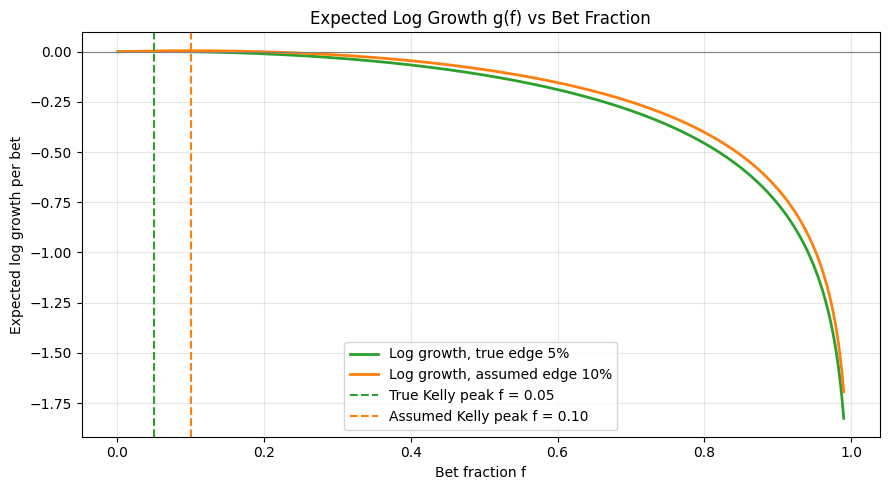

In [9]:
## 9. Overbetting and Estimation Error

# The key risk is sizing on a wrong edge. Here the true edge is 5% per bet, but the player sizes as if it is 10%. The expected log growth rate for a bet fraction f on an even-money-style bet with win probability p is

# g(f) = p·log(1 + f) + q·log(1 − f).

# Its maximum is the Kelly fraction. Sizing above the peak lowers growth and eventually makes it negative. We simulate the mis-sized player and plot g(f) for the true and estimated edges.

TRUE_EDGE = 0.05              # true win prob = 0.5 + edge/2 for even money
SIZED_EDGE = 0.10             # the player's estimate
p_true = 0.5 + TRUE_EDGE / 2
p_est = 0.5 + SIZED_EDGE / 2
f_true = 2 * p_true - 1       # Kelly for even-money bets
f_est = 2 * p_est - 1

N_SIM = 1000
bets = np.where(rng.random((N_SIM, N_DAYS)) < p_true, 1.0, -1.0)
wealth_mis = run_fixed_fraction(bets, f_est)
final_mis = wealth_mis[:, -1]

running_max = np.maximum.accumulate(wealth_mis, axis=1)
drawdown = 1 - wealth_mis / running_max
hit_50dd = np.mean(drawdown.max(axis=1) >= 0.50)

print(f"True edge: {TRUE_EDGE:.0%}  (p = {p_true:.3f}, Kelly f* = {f_true:.3f})")
print(f"Sized edge: {SIZED_EDGE:.0%}  (p = {p_est:.3f}, sized f = {f_est:.3f})")
print(f"Median final wealth:        {np.median(final_mis):.4f} x start")
print(f"P(end below start):         {np.mean(final_mis < START):.4f}")
print(f"P(50% drawdown at some point): {hit_50dd:.4f}")

def g(f, p):
    return p * np.log(1 + f) + (1 - p) * np.log(1 - f)

fs = np.linspace(0.001, 0.99, 400)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(fs, g(fs, p_true), color="tab:green", lw=2, label=f"Log growth, true edge {TRUE_EDGE:.0%}")
ax.plot(fs, g(fs, p_est), color="tab:orange", lw=2, label=f"Log growth, assumed edge {SIZED_EDGE:.0%}")
ax.axvline(f_true, color="tab:green", ls="--", label=f"True Kelly peak f = {f_true:.2f}")
ax.axvline(f_est, color="tab:orange", ls="--", label=f"Assumed Kelly peak f = {f_est:.2f}")
ax.axhline(0, color="gray", lw=0.8)
ax.set_title("Expected Log Growth g(f) vs Bet Fraction")
ax.set_xlabel("Bet fraction f")
ax.set_ylabel("Expected log growth per bet")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()